# Kalman filtering for the six COVID-19 waves

This notebook applies the same SIRD-based Kalman filter used in the original `kalman_base` notebook. The filtered input files contain positive COVID-19 records for each date window and are stored in `Datos`. All code, labels, titles, and summaries are written in English.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from codes import get_Y_obs, kalman_filter, SIRD_lineal

In [2]:
# The date ranges are inclusive.
DATA_DIR = Path.cwd().parent / "Datos"
POPULATION = 126_014_024
RECOVERY_DELAY_DAYS = 14

WAVES = [
    {"name": "Wave 1", "start": "2020-03-01", "end": "2020-07-31"},
    {"name": "Wave 2", "start": "2020-10-01", "end": "2021-02-28"},
    {"name": "Wave 3", "start": "2021-06-01", "end": "2021-09-30"},
    {"name": "Wave 4", "start": "2021-12-01", "end": "2022-02-28"},
    {"name": "Wave 5", "start": "2022-06-01", "end": "2022-08-31"},
    {"name": "Wave 6", "start": "2022-12-01", "end": "2023-01-31"},
]

BETA = 0.3508
GAMMA = 0.0714
DELTA = 0.0015
Q = np.diag([100.0, 100.0, 10.0])
R = np.diag([25.0, 25.0, 4.0])
P0 = np.diag([100.0, 100.0, 10.0])

_, F = SIRD_lineal(BETA, GAMMA, DELTA, s=1.0, dt=1.0)
H = np.eye(3)

for wave in WAVES:
    wave["csv"] = DATA_DIR / f"filtered_data_{wave['start']}_{wave['end']}.csv"
    if not wave["csv"].exists():
        raise FileNotFoundError(wave["csv"])

pd.DataFrame(WAVES)[["name", "start", "end", "csv"]]

,name,start,end,csv
0,Wave 1,2020-03-01,2020-07-31,/Users/marcosbautista/Documents/GitHub/Estimat...
1,Wave 2,2020-10-01,2021-02-28,/Users/marcosbautista/Documents/GitHub/Estimat...
2,Wave 3,2021-06-01,2021-09-30,/Users/marcosbautista/Documents/GitHub/Estimat...
3,Wave 4,2021-12-01,2022-02-28,/Users/marcosbautista/Documents/GitHub/Estimat...
4,Wave 5,2022-06-01,2022-08-31,/Users/marcosbautista/Documents/GitHub/Estimat...
5,Wave 6,2022-12-01,2023-01-31,/Users/marcosbautista/Documents/GitHub/Estimat...


## Kalman filtering

For each wave, the observations are constructed as cumulative cases, estimated recoveries, and cumulative deaths. The state vector is `[I, R, D]`, matching the original notebook.

In [3]:
results = {}

for wave in WAVES:
    df = pd.read_csv(wave["csv"])
    Y, observed = get_Y_obs(
        df,
        date_1=wave["start"],
        date_f=wave["end"],
        N=POPULATION,
        gamma_time=RECOVERY_DELAY_DAYS,
        date_col="FECHA_INGRESO",
    )

    x0 = Y[0].copy()
    x_filtered, covariance = kalman_filter(
        z=Y, F=F, H=H, Q=Q, R=R, x0=x0, P0=P0
    )
    filtered = pd.DataFrame(
        x_filtered,
        index=observed.index,
        columns=["I_filtered", "R_filtered", "D_filtered"],
    )
    results[wave["name"]] = {
        "observed": observed,
        "filtered": filtered,
        "covariance": covariance,
        "records": len(df),
    }

print(f"Processed {len(results)} waves.")

/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_7333/1858219504.py:4: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])
/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_7333/1858219504.py:4: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])


/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_7333/1858219504.py:4: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])
/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


Processed 6 waves.


/var/folders/sl/_0vv98412kq54qbqdd087ztw0000gn/T/ipykernel_7333/1858219504.py:4: DtypeWarning: Columns (0: PAIS_ORIGEN) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(wave["csv"])
/Users/marcosbautista/Documents/GitHub/Estimation-of-epidemiological-parameters/Codigos/codes.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA_DEF'] = pd.to_datetime(df['FECHA_DEF'], errors='coerce')


## Observed and filtered series

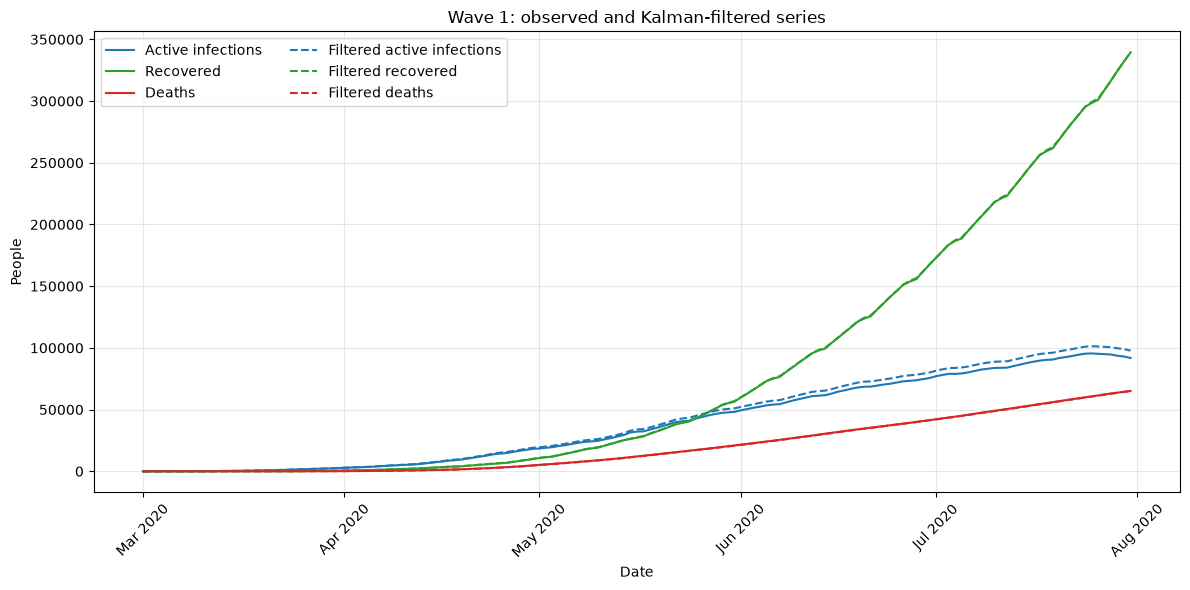

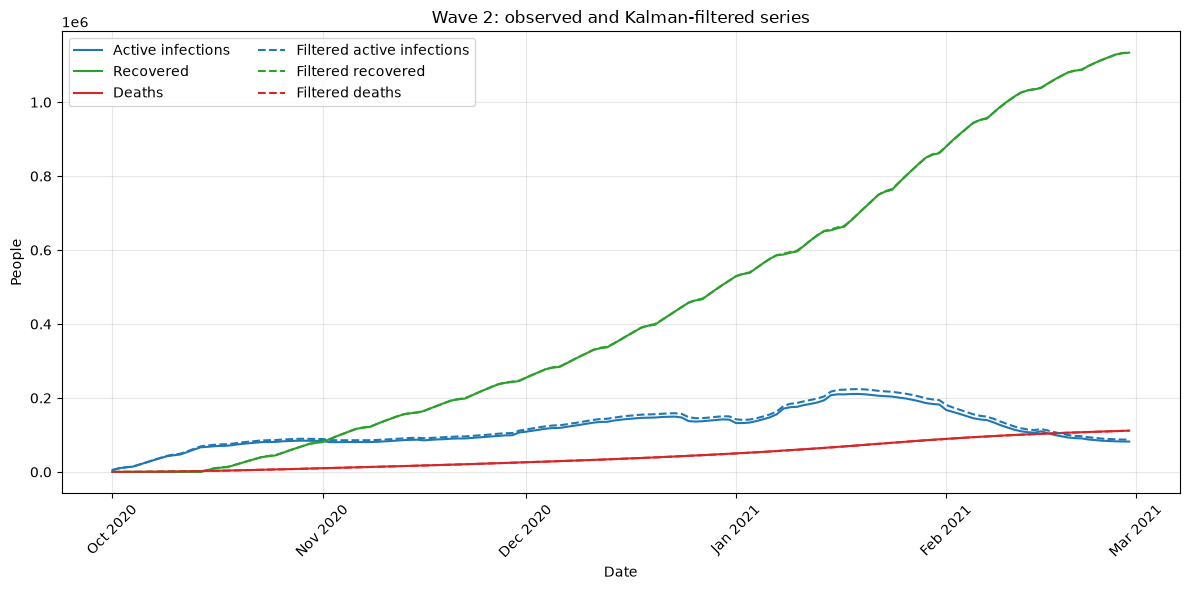

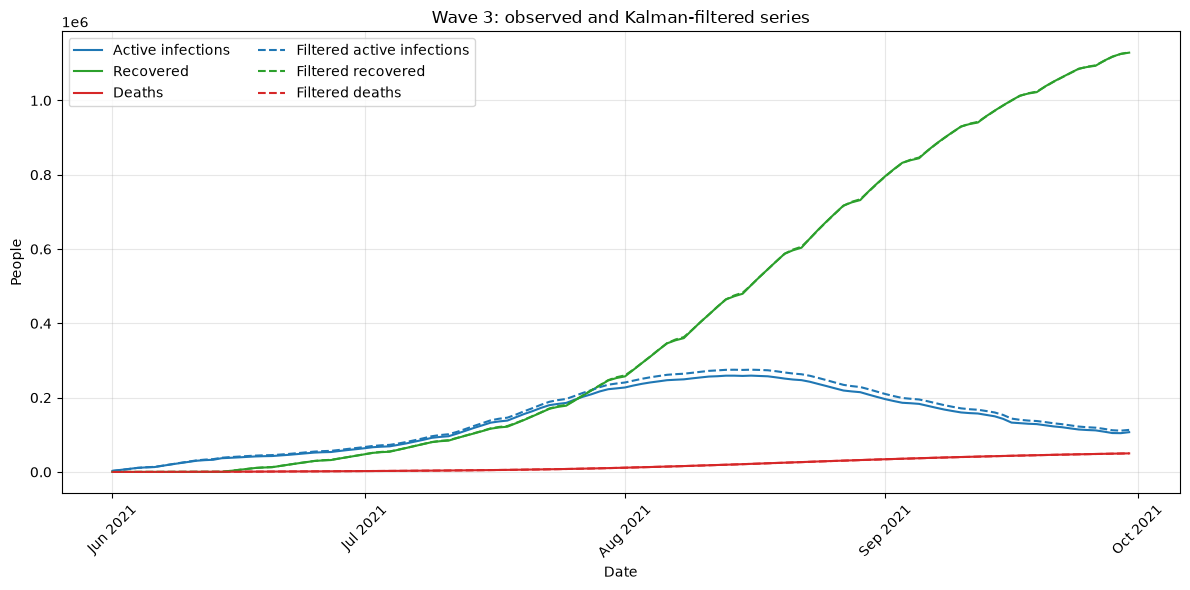

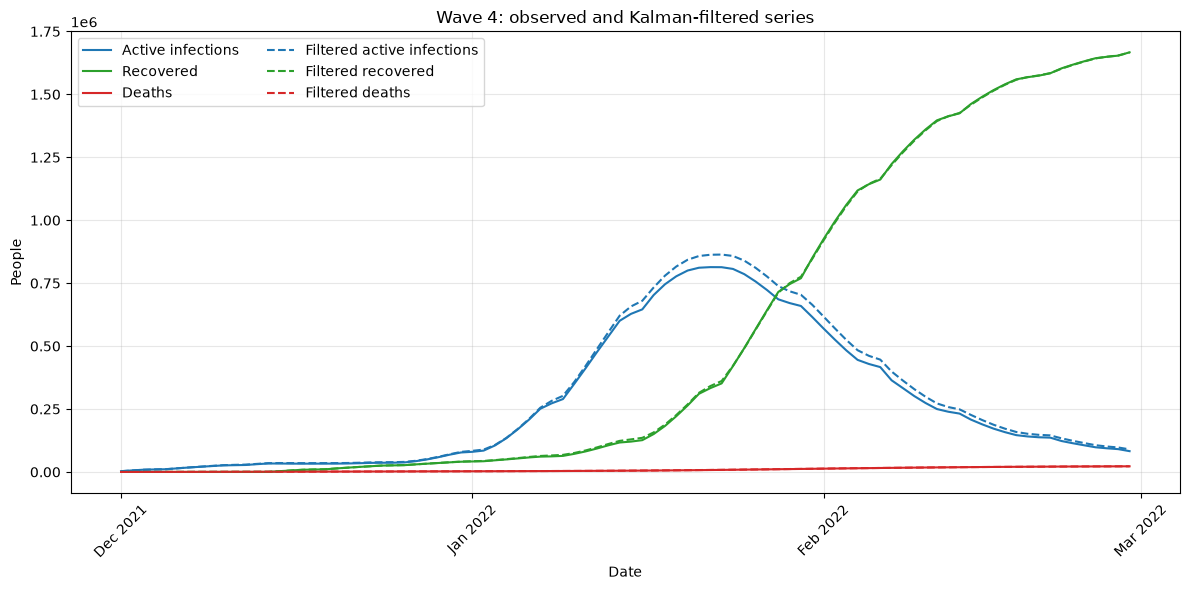

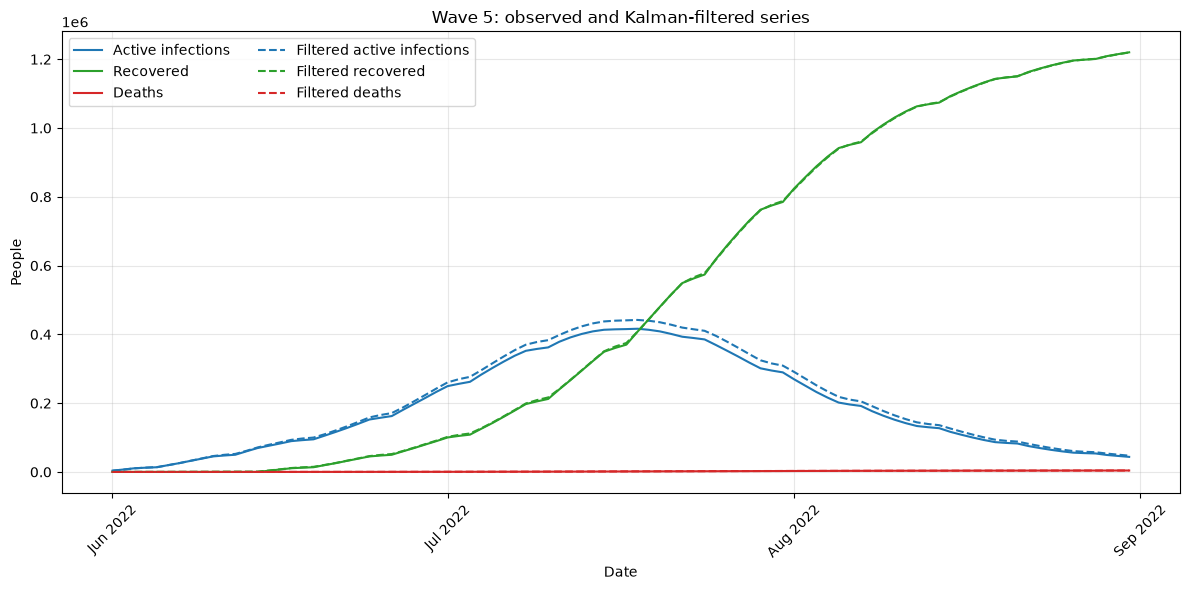

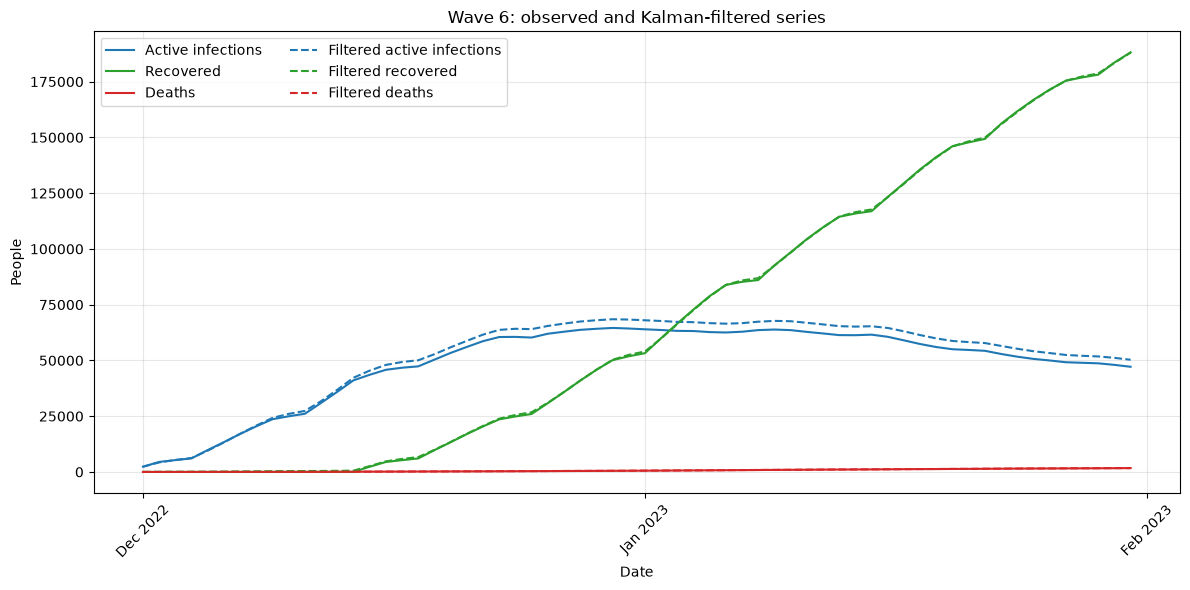

In [4]:
for wave in WAVES:
    name = wave["name"]
    observed = results[name]["observed"]
    filtered = results[name]["filtered"]

    fig, ax = plt.subplots(figsize=(12, 6))
    colors = {"I": "tab:blue", "R": "tab:green", "D": "tab:red"}
    labels = {"I": "Active infections", "R": "Recovered", "D": "Deaths"}
    filtered_labels = {
        "I_filtered": "Filtered active infections",
        "R_filtered": "Filtered recovered",
        "D_filtered": "Filtered deaths",
    }
    for column in ["I", "R", "D"]:
        ax.plot(observed.index, observed[column], color=colors[column], label=labels[column])
    for column in ["I_filtered", "R_filtered", "D_filtered"]:
        base_column = column[0]
        ax.plot(
            filtered.index, filtered[column], color=colors[base_column],
            linestyle="--", label=filtered_labels[column]
        )
    ax.set_title(f"{name}: observed and Kalman-filtered series")
    ax.set_xlabel("Date")
    ax.set_ylabel("People")
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()

## Wave summary

In [5]:
summary = []
for wave in WAVES:
    name = wave["name"]
    observed = results[name]["observed"]
    filtered = results[name]["filtered"]
    summary.append({
        "Wave": name,
        "Start": wave["start"],
        "End": wave["end"],
        "Records": results[name]["records"],
        "Observed cumulative cases": int(observed["C"].iloc[-1]),
        "Observed cumulative deaths": int(observed["D"].iloc[-1]),
        "Final filtered active infections": round(filtered["I_filtered"].iloc[-1], 2),
        "Final filtered recovered": round(filtered["R_filtered"].iloc[-1], 2),
        "Final filtered deaths": round(filtered["D_filtered"].iloc[-1], 2),
    })

summary = pd.DataFrame(summary)
summary

,Wave,Start,End,Records,Observed cumulative cases,Observed cumulative deaths,Final filtered active infections,Final filtered recovered,Final filtered deaths
0,Wave 1,2020-03-01,2020-07-31,496402,496402,65152,97782.49,339525.66,64989.98
1,Wave 2,2020-10-01,2021-02-28,1327809,1327809,111774,87319.17,1134829.89,111635.43
2,Wave 3,2021-06-01,2021-09-30,1285741,1285741,49993,113188.31,1129580.20,49931.75
3,Wave 4,2021-12-01,2022-02-28,1771962,1771962,22444,89666.58,1666039.58,22443.71
4,Wave 5,2022-06-01,2022-08-31,1268106,1268106,4168,47305.57,1219791.50,4187.01
5,Wave 6,2022-12-01,2023-01-31,237016,237016,1718,50306.23,188001.78,1733.69
